# 1 - Process raw Unity captures

In [ ]:
%load_ext autoreload
%autoreload 2

import os
import sys
from pathlib import Path

ROOT = Path.cwd()
while not (ROOT / "pyproject.toml").is_file():
    if ROOT.parent == ROOT:
        raise RuntimeError("run this notebook from inside the repository")
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
print("repo root:", ROOT)
print("python:  ", sys.version.split()[0], "->", sys.executable)

In [ ]:
import json

from IPython.display import Image, display

from perception.privileged_capture import process_capture
from perception.contracts import CaptureFrame, SSGSnapshot
from perception.ontology import load_ontology

In [3]:
ONTOLOGY = ROOT / "configs/ontology.json"
CAPTURE_ROOTS = sorted(
    path for path in (ROOT / "captures").iterdir() if (path / "raw").is_dir()
)

for path in CAPTURE_ROOTS:
    episodes = sorted(child.name for child in (path / "raw").iterdir() if child.is_dir())
    frames = sum(1 for _ in (path / "raw").rglob("*.json"))
    processed = (path / "annotations").is_dir()
    print(f"{path.name:24s} episodes={len(episodes):3d} raw_frames={frames:5d} "
          f"processed={processed}")

curriculum_run           episodes=155 raw_frames=14841 processed=False


In [4]:
reports = {}
for capture_root in CAPTURE_ROOTS:
    report = process_capture(capture_root, ONTOLOGY)
    reports[capture_root.name] = report
    print(f"{capture_root.name}: frames={report['frames_validated']} "
          f"instances={len(report['persistent_instance_ids'])} "
          f"stable_ids={report['stable_identity_verified']}")

curriculum_run: frames=14841 instances=985 stable_ids=True


In [5]:
report = reports[CAPTURE_ROOTS[0].name]
print("unavailable fields (not measurable from the simulator):")
for field in report["unavailable_fields"]:
    print("  -", field)
print("\nfirst capture records:", report["capture_records"][:3])
print("first oracle snapshots:", report["oracle_snapshots"][:3])

unavailable fields (not measurable from the simulator):
  - camera distortion coefficients
  - collision/contact events
  - physics velocity for objects without Rigidbody

first capture records: ['annotations/curriculum/000000.json', 'annotations/curriculum/000001.json', 'annotations/curriculum/000002.json']
first oracle snapshots: ['oracle/curriculum/000000.json', 'oracle/curriculum/000001.json', 'oracle/curriculum/000002.json']


In [6]:
ontology = load_ontology(ONTOLOGY)
print("ontology version:", ontology.ontology_version)

for capture_root in CAPTURE_ROOTS:
    annotations = sorted((capture_root / "annotations").rglob("*.json"))
    graphs = sorted((capture_root / "oracle").rglob("*.json"))
    for path in annotations:
        ontology.validate_capture(CaptureFrame.from_json_file(path))
    for path in graphs:
        ontology.validate_ssg(SSGSnapshot.from_json_file(path))
    print(f"{capture_root.name}: {len(annotations)} capture frames and "
          f"{len(graphs)} oracle graphs validated")

ontology version: 1.7.0
curriculum_run: 14841 capture frames and 14841 oracle graphs validated


episode: curriculum-0096 | frame: 57 | objects: 33
  curriculum-0096:instance-000001        SpawnerDispenserTall -> SpawnerDispenserTall p=1.00 visible=0.770769238
  curriculum-0096:instance-000002        GoodGoalMulti11 -> GoodGoalMulti    p=1.00 visible=None
  curriculum-0096:instance-000003        GoodGoalMulti11 -> GoodGoalMulti    p=1.00 visible=None
  curriculum-0096:instance-000004        SpawnerDispenserTall -> SpawnerDispenserTall p=1.00 visible=0.5322581
  curriculum-0096:instance-000005        SpawnerDispenserTall -> SpawnerDispenserTall p=1.00 visible=1.0
  curriculum-0096:instance-000006        GoodGoalMulti11 -> GoodGoalMulti    p=1.00 visible=0.181818187
  curriculum-0096:instance-000007        GoodGoalMulti10 -> GoodGoalMulti    p=1.00 visible=None
  curriculum-0096:instance-000008        GoodGoalMulti10 -> GoodGoalMulti    p=1.00 visible=0.0
  curriculum-0096:instance-000009        GoodGoalMulti10 -> GoodGoalMulti    p=1.00 visible=0.75
  curriculum-0096:instance-00001

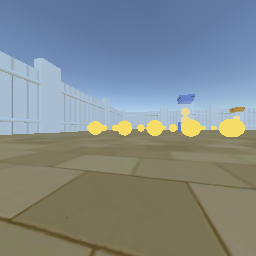

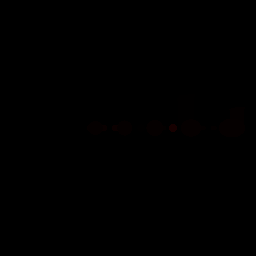

In [7]:
capture_root = CAPTURE_ROOTS[0]
sample = max(
    (path for path in (capture_root / "annotations").rglob("*.json")),
    key=lambda path: len(CaptureFrame.from_json_file(path).objects),
)
frame = CaptureFrame.from_json_file(sample)

print("episode:", frame.episode_id, "| frame:", frame.stamp.frame_index,
      "| objects:", len(frame.objects))
for item in frame.objects:
    top = max(item.semantic_distribution.entries, key=lambda entry: entry.probability)
    print(f"  {item.instance_id:38s} {item.exact_simulator_class:14s} -> "
          f"{top.label:16s} p={top.probability:.2f} visible={item.visibility_fraction}")

display(Image(filename=str(capture_root / frame.rgb.path)))
masks = {item.instance_mask.path for item in frame.objects if item.instance_mask}
for path in sorted(masks):
    display(Image(filename=str(capture_root / path)))